# 02 · Exploratory Data Analysis and Preprocessing
Course phases **3 (EDA)** and **4 (Preprocessing)**

**Builds on:** notebook 01 (`fdp.config`, `fdp.data`). **Commits:** `src/fdp/preprocess.py`, `reports/02_eda_preprocessing.json`, `reports/figures/02_*.png`.

**Rule we follow:** EDA and every preprocessing statistic use the **training block only** (Jan 15 – Aug 31). Looking at validation or test data while making decisions would be the "peeking" the worksheet warns about.

In [1]:
#@title ⚙️ 0 · Setup — run this cell first { display-mode: "form" }
#@markdown In **Colab** this clones the team repo and installs the requirements.
#@markdown Locally (Jupyter / VS Code) it just moves to the repo root.
REPO_URL = "https://github.com/mrstrange1708/T107_Flight_Delay_Prediction.git"  #@param {type:"string"}
BRANCH = "main"  #@param {type:"string"}
QUICK_RUN = False  #@param {type:"boolean"}
#@markdown `QUICK_RUN` = smaller searches/samples so the notebook finishes in a few minutes (use it to check the code runs; turn it OFF for the final numbers you commit).

import os, sys, subprocess
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    if not os.path.isdir("/content/T107_Flight_Delay_Prediction/.git"):
        subprocess.run(["git", "clone", "-q", "-b", BRANCH, REPO_URL, "/content/T107_Flight_Delay_Prediction"], check=True)
    os.chdir("/content/T107_Flight_Delay_Prediction")
    if os.path.exists("requirements.txt"):
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
for d in ["src/fdp", "tests", "data/raw", "data/processed", "reports/figures"]:
    os.makedirs(d, exist_ok=True)
open("src/fdp/__init__.py", "a").close()
sys.path.insert(0, os.path.abspath("src"))

import warnings; warnings.filterwarnings("ignore")
import json, importlib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
print("Working directory:", os.getcwd(), "| Colab:", IN_COLAB, "| QUICK_RUN:", QUICK_RUN)

Working directory: /Users/shaikjunaidsami/Desktop/T107_Flight_Delay_Prediction | Colab: False | QUICK_RUN: False


In [2]:
import fdp.config as config, fdp.data as data
df = data.build_dataset(*data.load_raw())
S = data.split(df)
train = S["train"]                                    # labelled training flights
train_all = df[(df["date"] >= config.SPLITS["train"][0]) & (df["date"] <= config.SPLITS["train"][1])]  # incl. cancelled
print(f"training block: {len(train_all):,} scheduled flights, {len(train):,} labelled")

training block: 212,702 scheduled flights, 205,642 labelled


---
## Part A · Phase 3 — EDA, following the worksheet's 7-point checklist
| # | Check | Section |
|---|---|---|
| 1 | Dataset structure | A1 |
| 2 | Missing values (random or systematic?) | A2 |
| 3 | Outliers | A3 |
| 4 | Duplicates | A4 |
| 5 | Distributions | A5 |
| 6 | Relationships | A6 |
| 7 | Class imbalance | A7 |

### A1 · Structure

In [3]:
print(train_all.shape)
train_all.dtypes.value_counts()

(212702, 31)


int64             13
float64           10
str                5
bool               2
datetime64[us]     1
Name: count, dtype: int64

### A2 · Missing values: how many, and random or systematic?

In [4]:
cols = ["dep_time", "dep_delay", "arr_time", "arr_delay", "air_time", "plane_year", "plane_seats", "tailnum"]
miss = pd.DataFrame({
    "missing_%": [round(100 * (train_all[c].isna() | (train_all[c] == "UNKNOWN")).mean(), 2) for c in cols]}, index=cols)
miss

,missing_%
dep_time,2.93
dep_delay,2.93
arr_time,3.08
arr_delay,3.32
air_time,3.32
plane_year,17.47
plane_seats,15.87
tailnum,0.90


In [5]:
# Is aircraft data missing at random? Check by carrier.
by_carrier = (train_all.groupby("carrier")["plane_year"].apply(lambda s: s.isna().mean()).sort_values(ascending=False) * 100).round(1)
by_carrier.head(6)

carrier
MQ    95.1
AA    69.5
FL     9.7
HA     9.6
F9     8.1
9E     7.6
Name: plane_year, dtype: float64

**Reading this:**
* `dep_time … air_time` are missing exactly for **cancelled / diverted** flights. That is *systematic* (it has a cause), and those columns are outcomes we never use as inputs anyway.
* Aircraft year/seats are missing mostly for **two carriers** (MQ, AA: their tail numbers are not in the planes table). Also systematic. So we **impute the median and add a missing-indicator column**: the model can learn "this carrier's aircraft is unknown" instead of us hiding it. Deleting these rows would drop ~17% of flights and bias the data against two airlines (the worksheet's deletion rule is for < 1–2% missing).

### A3 · Outliers

count    205642.0
mean          9.4
std          47.7
min         -86.0
50%          -4.0
90%          61.0
99%         204.0
max        1127.0
IQR outliers: 9.1% of flights | skewness 3.36


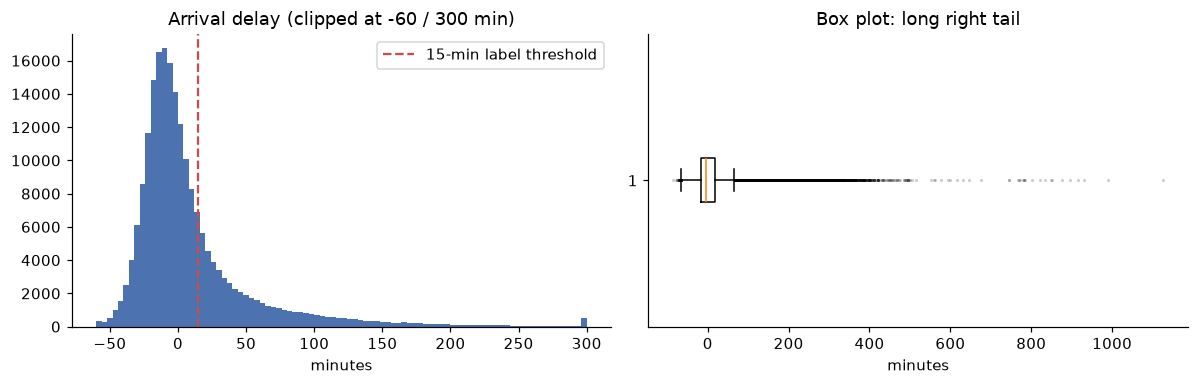

In [6]:
from scipy import stats
d = train["arr_delay"]
q1, q3 = d.quantile([.25, .75]); iqr = q3 - q1
outlier_share = float(((d < q1 - 1.5 * iqr) | (d > q3 + 1.5 * iqr)).mean())
desc = d.describe(percentiles=[.5, .9, .99]).round(1)
print(desc.to_string()); print(f"IQR outliers: {100*outlier_share:.1f}% of flights | skewness {stats.skew(d):.2f}")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].hist(d.clip(-60, 300), bins=90, color="#4C72B0"); ax[0].axvline(15, color="#C44E52", ls="--", label="15-min label threshold")
ax[0].set(title="Arrival delay (clipped at -60 / 300 min)", xlabel="minutes"); ax[0].legend()
ax[1].boxplot(d, vert=False, showfliers=True, flierprops={"markersize": 1, "alpha": .2}); ax[1].set(title="Box plot: long right tail", xlabel="minutes")
fig.tight_layout(); fig.savefig("reports/figures/02_arr_delay_distribution.png"); plt.show()

**Decision: keep outliers.** A 5-hour delay is a real event, not a typing error, and our label only asks *was it ≥ 15 minutes?* Its size cannot distort a yes/no label. This skew is also **why we classify instead of regressing on minutes**: a regression model would chase a handful of multi-hour delays.

### A4 · Duplicates

In [7]:
key = ["date", "carrier", "flight", "origin", "sched_dep_time"]
n_dup_rows = int(train_all.duplicated().sum()); n_dup_key = int(train_all.duplicated(key).sum())
print("fully duplicated rows:", n_dup_rows, "| duplicated (date, carrier, flight, origin, scheduled time):", n_dup_key)

fully duplicated rows: 0 | duplicated (date, carrier, flight, origin, scheduled time): 0


### A5–A6 · Distributions and relationships

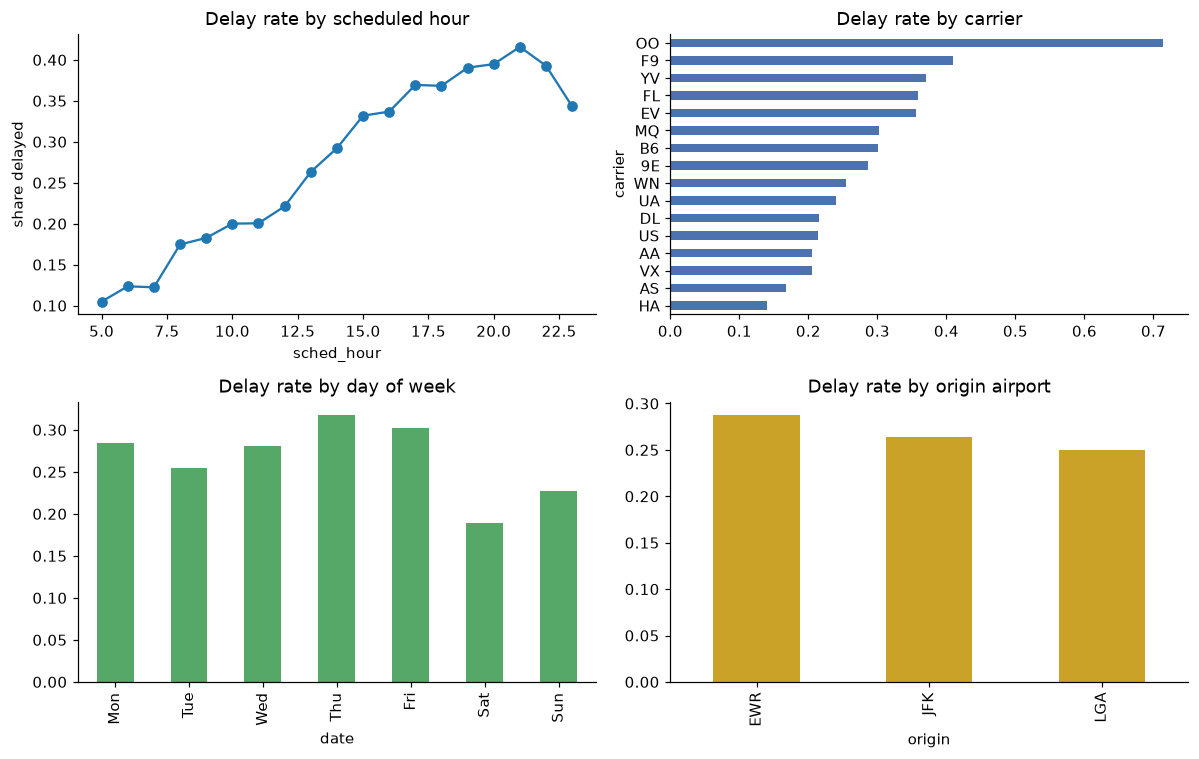

hour 5: 0.105  ->  hour 20: 0.395


In [8]:
by_hour = train.groupby("sched_hour")["delayed"].mean()
by_carrier_rate = train.groupby("carrier")["delayed"].mean().sort_values()
by_dow = train.groupby(train["date"].dt.day_of_week)["delayed"].mean()
by_origin = train.groupby("origin")["delayed"].mean()
fig, ax = plt.subplots(2, 2, figsize=(11, 7))
by_hour.plot(ax=ax[0, 0], marker="o", title="Delay rate by scheduled hour", ylabel="share delayed")
by_carrier_rate.plot.barh(ax=ax[0, 1], title="Delay rate by carrier", color="#4C72B0")
by_dow.rename(index=dict(enumerate("Mon Tue Wed Thu Fri Sat Sun".split()))).plot.bar(ax=ax[1, 0], title="Delay rate by day of week", color="#55A868")
by_origin.plot.bar(ax=ax[1, 1], title="Delay rate by origin airport", color="#C9A227")
fig.tight_layout(); fig.savefig("reports/figures/02_delay_rate_relationships.png"); plt.show()
print(f"hour 5: {by_hour.loc[5]:.3f}  ->  hour 20: {by_hour.loc[20]:.3f}")

**What this tells the feature engineer (notebook 03):**
* Delay risk **rises through the day**: a late plane stays late for its next legs (delay propagation). So time of day must be a feature.
* Carriers differ by more than 2×, so carrier and its recent delay history matter.
* Saturdays are calmer, so day of week matters.

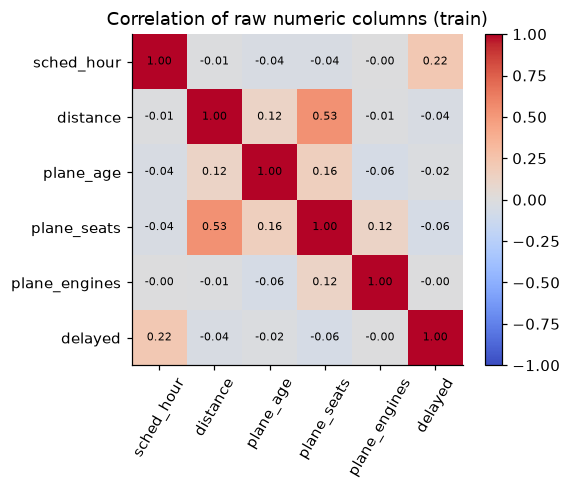

In [9]:
num = ["sched_hour", "distance", "plane_age", "plane_seats", "plane_engines", "delayed"]
corr = train[num].corr()
fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(num))); ax.set_xticklabels(num, rotation=60); ax.set_yticks(range(len(num))); ax.set_yticklabels(num)
for i in range(len(num)):
    for j in range(len(num)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(im); ax.set_title("Correlation of raw numeric columns (train)")
fig.tight_layout(); fig.savefig("reports/figures/02_correlation.png"); plt.show()

Raw columns correlate weakly with the label (strongest: scheduled hour). Seats and engines correlate with each other (bigger planes), a first hint of the **multicollinearity** that notebook 03 checks with VIF. Weak raw correlations are the reason feature engineering matters so much here.

### Time view: does yesterday predict today?
The data are time-indexed, so we look at the **daily share of delayed flights** as a time series. Its autocorrelation (ACF) and partial autocorrelation (PACF) tell notebook 03 **how far back history features should look**.

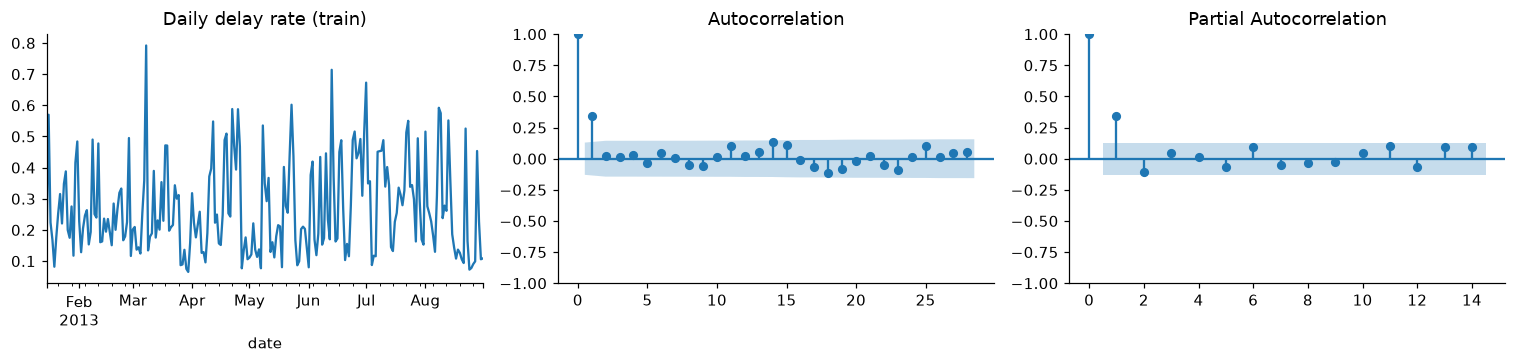

ACF lag1 0.343 | lag7 0.008 | PACF lag1 0.345 | lag2 -0.109 | ADF p-value 0.0000


In [10]:
from statsmodels.tsa.stattools import acf, pacf, adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
daily = train.groupby("date")["delayed"].mean().asfreq("D").interpolate()
a, pa = acf(daily, nlags=28), pacf(daily, nlags=14)
adf_stat, adf_p = adfuller(daily)[:2]
fig, ax = plt.subplots(1, 3, figsize=(14, 3.4))
daily.plot(ax=ax[0], title="Daily delay rate (train)")
plot_acf(daily, lags=28, ax=ax[1]); plot_pacf(daily, lags=14, ax=ax[2], method="ywm")
fig.tight_layout(); fig.savefig("reports/figures/02_daily_acf_pacf.png"); plt.show()
print(f"ACF lag1 {a[1]:.3f} | lag7 {a[7]:.3f} | PACF lag1 {pa[1]:.3f} | lag2 {pa[2]:.3f} | ADF p-value {adf_p:.4f}")

**Reading it:**
* **Lag 1 is clearly positive** and the PACF drops after lag 1: bad days follow bad days, and *yesterday* carries most of that memory (an AR(1)-like pattern). → a **1-day** history window.
* **Lag 7 is about zero.** So there is no week-to-week memory in the overall delay rate; the weekly pattern seen in A6 (calm Saturdays) is a fixed day-of-week effect, which we capture with **day-of-week features**, not with history.
* Why still use **7- and 28-day** windows? A single carrier, route or flight number has few flights per day, so a 1-day rate is noisy. Longer windows trade recency for stability (a bias–variance trade-off). Notebook 03's feature-group tests check whether they help.
* ADF p < 0.05: no unit root, so a bad day's shock fades and the daily rate returns to its mean. That makes the lag-1 pattern a stable property, not a trend artefact. It does **not** mean the level is constant all year: notebook 01 shows the monthly rate shifting.

### A7 · Class imbalance

In [11]:
rate = float(train["delayed"].mean())
print(f"Delayed share in training: {rate:.3f}  (about 1 in {1/rate:.1f} flights)")

Delayed share in training: 0.268  (about 1 in 3.7 flights)


About 1 in 4 flights is delayed: **imbalanced, but only moderately** (the worksheet's warning case is 95/5). Decisions:
* Use PR AUC / precision / recall, not accuracy (notebook 01).
* **No SMOTE or under-sampling.** Re-sampling changes the class ratio the model sees, which distorts its probabilities; we need honest probabilities for the flag list.

---
## Part B · Phase 4 — Preprocessing
The worksheet's four steps, applied to our data:

| Step | Our decision | Why |
|---|---|---|
| 1. Missing values | Median imputation + missing-indicator for aircraft columns. Rows with no label are excluded from training, never imputed. | Missingness is systematic (A2); deleting 17% of rows would bias two airlines. |
| 2. Inconsistent data | Times stored as HHMM (e.g. 1530) are converted to minutes after midnight; 2400 → 0. Unknown tail numbers → `"UNKNOWN"`. No duplicates (A4). | 1530 − 1459 is not 31 minutes in HHMM; minutes make arithmetic correct. |
| 3. Scaling | **Logistic regression:** z-score (compared with robust below). **Trees / boosting:** no scaling. | Gradient descent needs comparable feature scales. Trees split on thresholds, so scale changes nothing. |
| 4. Encoding | **Logistic regression:** one-hot (carrier 16, origin 3, dest ~105; levels with < 50 training flights grouped). **Trees:** ordinal codes; XGBoost uses native categorical splits. | One-hot avoids fake order for linear models. Codes are safe for trees (worksheet Reflect 5). With ~105 destinations one-hot is still manageable; binary encoding would mix unrelated airports in the same bit. |

**Leakage rule (Phase 5 warning):** imputation medians, scaling means and the category list are learned **from training rows only**. The scikit-learn `Pipeline` guarantees it: `.fit()` only sees the rows passed to it.

In [12]:
%%writefile src/fdp/preprocess.py
"""Phase 4 preprocessing: missing values, scaling, encoding.

Rule from the course (Phase 5 warning): every statistic used for imputation or scaling is FIT ON
THE TRAINING ROWS ONLY and then applied to validation/test. Wrapping the steps in a scikit-learn
Pipeline guarantees that, because .fit() only ever sees the rows it is given.
"""
import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, RobustScaler, StandardScaler


def linear_preprocessor(numeric, categorical, scaler: str = "standard"):
    """For gradient-based / linear models (logistic regression).

    numeric:     median imputation + missing-indicator column, then scaling (z-score or robust).
    categorical: one-hot; categories seen < 50 times in training are grouped as 'infrequent',
                 and unseen categories at test time map to that group instead of crashing.
    """
    sc = StandardScaler() if scaler == "standard" else RobustScaler()
    return ColumnTransformer([
        ("num", make_pipeline(SimpleImputer(strategy="median", add_indicator=True), sc), list(numeric)),
        ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=50), list(categorical)),
    ])


def tree_preprocessor(numeric, categorical):
    """For tree models (decision tree, random forest).

    Trees split on thresholds, so scaling changes nothing and is skipped. Label/ordinal codes are
    safe for trees (no distances are computed). Unseen categories get code -1.
    """
    return ColumnTransformer([
        ("num", SimpleImputer(strategy="median", add_indicator=True), list(numeric)),
        ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), list(categorical)),
    ])


def iqr_outlier_share(x) -> float:
    x = np.asarray(x, dtype=float)
    x = x[~np.isnan(x)]
    q1, q3 = np.percentile(x, [25, 75])
    return float(((x < q1 - 1.5 * (q3 - q1)) | (x > q3 + 1.5 * (q3 - q1))).mean())

Overwriting src/fdp/preprocess.py


In [13]:
#@title 🎛️ Scaler for the linear model { display-mode: "form" }
SCALER = "standard"  #@param ["standard", "robust"]
import fdp.preprocess as prep; importlib.reload(prep)
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score

raw_num = ["sched_hour", "distance", "plane_age", "plane_seats", "plane_engines"]
valid = S["valid"]
results = {}
for name in ["standard", "robust"]:
    pipe = make_pipeline(prep.linear_preprocessor(raw_num, config.CATEGORICAL, scaler=name), LogisticRegression(max_iter=3000))
    pipe.fit(train, train["delayed"].astype(int))
    results[name] = {"valid_pr_auc": round(average_precision_score(valid["delayed"], pipe.predict_proba(valid)[:, 1]), 4),
                     "lbfgs_iterations": int(pipe[-1].n_iter_[0])}
pd.DataFrame(results).T

,valid_pr_auc,lbfgs_iterations
standard,0.1974,67.0
robust,0.1978,44.0


Both scalers give practically the same validation PR AUC on these columns (the robust one converges in fewer iterations). We keep the **z-score (standard)** scaler as the default; the form lets you switch. The robust scaler would matter for heavy-outlier columns, which we do not feed to the model (delay minutes are outcomes, not inputs).

In [14]:
# Proof that preprocessing statistics come from TRAINING rows only
pre = prep.linear_preprocessor(raw_num, config.CATEGORICAL).fit(train)
imputer = pre.named_transformers_["num"][0]
print("median plane_age learned by the imputer :", imputer.statistics_[raw_num.index("plane_age")])
print("median plane_age in training rows       :", train["plane_age"].median())
print("median plane_age in ALL rows (not used) :", df["plane_age"].median())
Z = pre.transform(valid)
print("validation matrix after preprocessing  :", Z.shape, "(numeric + missing indicators + one-hot)")

median plane_age learned by the imputer : 11.0
median plane_age in training rows       : 11.0
median plane_age in ALL rows (not used) : 11.0
validation matrix after preprocessing  : (27010, 120) (numeric + missing indicators + one-hot)


In [15]:
out = {"missing_pct": miss["missing_%"].to_dict(), "plane_year_missing_by_carrier_top": by_carrier.head(6).to_dict(),
       "arr_delay": {k: float(v) for k, v in desc.items()}, "arr_delay_skew": round(float(stats.skew(d)), 3),
       "iqr_outlier_share": round(outlier_share, 4), "duplicates_full": n_dup_rows, "duplicates_key": n_dup_key,
       "delay_rate_by_hour": {int(k): round(float(v), 4) for k, v in by_hour.items()},
       "delay_rate_by_carrier": {k: round(float(v), 4) for k, v in by_carrier_rate.items()},
       "delay_rate_by_dow": {int(k): round(float(v), 4) for k, v in by_dow.items()},
       "delay_rate_by_origin": {k: round(float(v), 4) for k, v in by_origin.items()},
       "acf": {"lag1": round(float(a[1]), 3), "lag7": round(float(a[7]), 3), "lag14": round(float(a[14]), 3)},
       "pacf": {"lag1": round(float(pa[1]), 3), "lag2": round(float(pa[2]), 3)}, "adf_p": float(adf_p),
       "train_delay_rate": round(rate, 4), "scaler_comparison": results, "chosen_scaler": SCALER}
with open("reports/02_eda_preprocessing.json", "w") as f:
    json.dump(out, f, indent=2)
print("saved reports/02_eda_preprocessing.json")

saved reports/02_eda_preprocessing.json


---
## Summary
* Missing aircraft data are systematic (two carriers) → median + indicator, fitted on train.
* Delays are heavily right-skewed → keep outliers; classify instead of regress.
* Risk rises through the day, differs by carrier and weekday → features for notebook 03.
* Daily delay rate: yesterday matters most (lag-1 ACF), no week-to-week memory (lag-7 ≈ 0) → 1-day history window, day-of-week features, and 7/28-day windows only where groups are small.
* Moderate imbalance (~27% delayed in training) → PR AUC, no re-sampling.

**Next:** notebook 03 turns these findings into features.

<details><summary><b>Viva questions for this notebook (click)</b></summary>

1. **Why do EDA on the training block only?** Decisions made while looking at validation/test data leak information into the model design.
2. **Missing aircraft data: delete or impute?** Impute (median + indicator). It is about 17% of rows and concentrated in two airlines, so deleting would bias the data; the indicator keeps the "unknown aircraft" signal.
3. **Why keep outliers?** They are real delays and the binary label is unaffected by their size.
4. **Read the ACF/PACF.** Strong lag-1 ACF and a PACF cut-off after lag 1 → yesterday carries the signal (AR(1)-like) → 1-day window. Lag-7 ACF ≈ 0 → the weekly effect is a fixed day-of-week pattern, handled by day-of-week features; longer windows are only for stability.
5. **Why no SMOTE?** Imbalance is moderate and re-sampling distorts predicted probabilities.
6. **Why scale for logistic regression but not for trees?** Gradient descent and L2 penalties depend on feature scale; tree splits do not.
7. **Why one-hot for LR but ordinal codes for trees?** Integer codes imply a fake order to a linear model; a tree only asks "code ≤ k?", so codes are safe.
</details>

In [16]:
#@title 📦 Last step · download the files you must commit { display-mode: "form" }
#@markdown Downloads a zip with your module(s) and results. Also do **File → Download → Download .ipynb** (keeps the outputs).
#@markdown Unzip both into your local clone of the repo and commit them.
import glob, zipfile
FILES = [
    'src/fdp/preprocess.py',
    'reports/02_eda_preprocessing.json',
    'reports/figures/02_*.png',
]
paths = sorted({p for pattern in FILES for p in glob.glob(pattern)})
zip_name = "02_outputs.zip"
with zipfile.ZipFile(zip_name, "w") as z:
    for p in paths:
        z.write(p)
print("Packed", len(paths), "files into", zip_name)
for p in paths:
    print("  ", p)
if IN_COLAB:
    from google.colab import files
    files.download(zip_name)

Packed 6 files into 02_outputs.zip
   reports/02_eda_preprocessing.json
   reports/figures/02_arr_delay_distribution.png
   reports/figures/02_correlation.png
   reports/figures/02_daily_acf_pacf.png
   reports/figures/02_delay_rate_relationships.png
   src/fdp/preprocess.py
